# Анализ данных и проверка гипотез
**Датасет:** Kickstarter Projects (ks-projects-201801.csv).  
**Задача:** бинарная классификация (соберёт проект нужную сумму или нет).

Для анализа берём случайные 25% очищенных данных. На оставшихся 75% проверяем гипотезы.

## 1 Загрузка данных и библиотек
Используем тот же датасет, что и в прошлой работе. Одна строка - один проект Kickstarter.
Файл `ks-projects-201801.csv` должен лежать в одной папке с блокнотом.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 30)

In [2]:
raw = pd.read_csv(Path('ks-projects-201801.csv'))
print('Исходный размер:', raw.shape)

Исходный размер: (378661, 15)


In [3]:
display(raw.head())
display(pd.DataFrame({'тип': raw.dtypes.astype(str), 'пропуски': raw.isna().sum(),
                      'уникальных': raw.nunique()}))
print('Полные дубликаты:', raw.duplicated().sum())
print('Повторы ID:', raw.ID.duplicated().sum())
print('Повторы названия (не основание удаления):', raw.name.duplicated().sum())

Полные дубликаты: 0
Повторы ID: 0
Повторы названия (не основание удаления): 2896


,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


,тип,пропуски,уникальных
ID,int64,0,378661
name,object,4,375764
category,object,0,159
main_category,object,0,15
currency,object,0,14
deadline,object,0,3164
goal,float64,0,8353
launched,object,0,378089
pledged,float64,0,62130
state,object,0,6


## 2 Очистка данных
Проверяем данные по шагам. После каждого удаления выводим число удалённых и оставшихся строк.

In [4]:
# Работаем с копией, чтобы исходные данные остались доступны.
d = raw.copy()
log = []  # сюда записываем число удалённых строк
repairs = []  # сюда записываем исправления пропусков

### 2.1 Дубликаты
Удаляем полные копии. ID должен быть уникальным. Одинаковые названия разных проектов оставляем: это могут быть разные кампании или повторные запуски.

In [5]:
before = len(d)
d = d.loc[~d.duplicated()].copy()  # оставляем подходящие строки
log.append({'правило': 'Полные дубликаты', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))
assert d.ID.notna().all(), 'Пропущен ключ: нужна проверка источника'
assert d.ID.is_unique, 'Конфликт ID: нужна ручная проверка'

Удалено: 0 Осталось: 378661


### 2.2 Числовые значения
Цель должна быть больше нуля, сборы и число спонсоров - неотрицательными. Число спонсоров должно быть целым. Неправильные значения и пропуски в этих полях удаляем.

In [6]:
numeric = ['goal', 'usd_goal_real', 'pledged', 'usd_pledged_real', 'backers']
for col in numeric:
    d[col] = pd.to_numeric(d[col], errors='coerce')
for col in ['launched', 'deadline']:
    d[col] = pd.to_datetime(d[col], errors='coerce')
valid_numbers = np.isfinite(d[numeric]).all(axis=1)
valid_numbers &= (d[['goal', 'usd_goal_real']] > 0).all(axis=1)
valid_numbers &= (d[['pledged', 'usd_pledged_real', 'backers']] >= 0).all(axis=1)
valid_numbers &= d.backers.eq(np.floor(d.backers))
before = len(d)
d = d.loc[valid_numbers].copy()  # оставляем подходящие строки
log.append({'правило': 'Некорректные числа / обязательные значения', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))

Удалено: 0 Осталось: 378661


### 2.3 Даты
Оставляем даты запуска с 2009 года по январь 2018 года - период исходного датасета. Дедлайн не должен быть раньше даты запуска. Сравниваем календарные даты, потому что время дедлайна не указано.

In [7]:
valid_dates = d.launched.between('2009-01-01', '2018-01-31 23:59:59')
valid_dates &= d.deadline.notna() & (d.deadline >= d.launched.dt.normalize())
before = len(d)
d = d.loc[valid_dates].copy()  # оставляем подходящие строки
log.append({'правило': 'Ошибка даты запуска или порядка дат', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))

Удалено: 7 Осталось: 378654


### 2.4 Статус проекта
Как и раньше, оставляем successful и failed. Отменённые, заблокированные и ещё идущие кампании не подходят для нашей бинарной задачи.

In [8]:
before = len(d)
d = d.loc[d.state.isin(['successful', 'failed'])].copy()  # оставляем подходящие строки
log.append({'правило': 'Вне бинарной задачи', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))

Удалено: 46979 Осталось: 331675


### 2.5 Совпадение статуса и суммы
Успешный проект должен собрать не меньше цели, провалившийся - меньше. Сравниваем суммы в исходной валюте. Противоречивые строки удаляем: даже если небольшая разница вызвана округлением, исправлять статус без исходных данных нельзя.

In [9]:
mismatch = ((d.state.eq('successful') & d.pledged.lt(d.goal)) |
            (d.state.eq('failed') & d.pledged.ge(d.goal)))
conflicts = d.loc[mismatch, ['ID', 'state', 'goal', 'pledged']].copy()
before = len(d)
d = d.loc[~mismatch].copy()  # оставляем подходящие строки
log.append({'правило': 'Статус противоречит сумме', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))
display(conflicts)  # строки с противоречивым статусом

Удалено: 11 Осталось: 331664


,ID,state,goal,pledged
16780,1085047405,failed,23000.0,23020.01
58558,1297794474,failed,3000.0,3087.50
72483,1368992939,successful,3600.0,3599.69
136909,1695255515,failed,3600.0,3600.00
151490,1769772834,successful,36000.0,30716.00
216545,2103203254,failed,10000.0,10797.00
232422,251325270,successful,8000.0,7999.65
275777,4732285,successful,2000.0,1999.66
298960,59246799,failed,6000.0,6183.00
335859,780863434,successful,25000.0,24892.50


### 2.6 Пропуски в названии
Отсутствующее название заменяем пустой строкой. Так при подсчёте длины названия получим 0.

In [10]:
missing_name = d.name.isna() | d.name.fillna('').str.strip().eq('')
repairs.append({'поле': 'name', 'исправлено': int(missing_name.sum()), 'действие': 'Пустая строка'})
d['name'] = d.name.fillna('').str.strip()
print('Заполнено названий:', int(missing_name.sum()))

Заполнено названий: 3


### 2.7 Страна и другие категории
Ошибочную страну `N,0"` и пустые категории заменяем на `Unknown`. Угадать правильное значение по остальным полям нельзя.

In [11]:
for col in ['country', 'currency', 'category', 'main_category']:
    d[col] = d[col].astype('string').str.strip().replace({'': pd.NA, 'N,0"': pd.NA})
    repairs.append({'поле': col, 'исправлено': int(d[col].isna().sum()), 'действие': 'Unknown'})
    d[col] = d[col].fillna('Unknown').astype(str)
display(pd.DataFrame(repairs))

,поле,исправлено,действие
0,name,3,Пустая строка
1,country,210,Unknown
2,currency,0,Unknown
3,category,0,Unknown
4,main_category,0,Unknown


### 2.8 Повторяющийся показатель сбора
Удаляем `usd pledged`: это ещё одна запись итогового сбора, в исходном файле у неё 3797 пропусков. Другие USD-столбцы рассчитаны по другому курсу, поэтому заполнять ими пропуски некорректно.

In [12]:
repairs.append({'поле': 'usd pledged', 'исправлено': int(d['usd pledged'].isna().sum()),
                'действие': 'Удалён дублирующий итоговый столбец'})
d = d.drop(columns=['usd pledged'])
print('Столбец usd pledged удалён')

Столбец usd pledged удалён


### 2.9 Длительность и целевая переменная
Считаем длительность в календарных днях. Успешному проекту присваиваем target = 1, провалившемуся - 0. Очень большие положительные цели оставляем: сами по себе они не ошибка.

In [13]:
d['duration_days'] = (d.deadline - d.launched.dt.normalize()).dt.days
d['target'] = d.state.eq('successful').astype('int8')
assert d.ID.is_unique and not d.isna().any().any()
assert (d.duration_days >= 0).all()

### 2.10 Итог очистки
Проверяем пропуски и смотрим, сколько строк убрало каждое правило. Одна строка учитывается только при первом удалении.

In [14]:
clean = d.copy()
cleaning_log = pd.DataFrame(log)
repairs = pd.DataFrame(repairs)
display(cleaning_log)
display(repairs)
print('Осталось строк:', len(clean))
print('Пропусков:', clean.isna().sum().sum())
print('Доля успешных:', round(clean.target.mean(), 4))

Осталось строк: 331664
Пропусков: 0
Доля успешных: 0.4039


,правило,удалено,осталось
0,Полные дубликаты,0,378661
1,Некорректные числа / обязательные значения,0,378661
2,Ошибка даты запуска или порядка дат,7,378654
3,Вне бинарной задачи,46979,331675
4,Статус противоречит сумме,11,331664


,поле,исправлено,действие
0,name,3,Пустая строка
1,country,210,Unknown
2,currency,0,Unknown
3,category,0,Unknown
4,main_category,0,Unknown
5,usd pledged,210,Удалён дублирующий итоговый столбец


## 3 Разделение данных
Берём случайные 25% с `random_state=42`, чтобы результат можно было повторить.
Остальные 75% пока не используем. Гипотезы и границы групп выбираем по первой части.

In [15]:
eda = clean.sample(frac=0.25, random_state=SEED).copy()
confirmation = clean.drop(index=eda.index).copy()
assert set(eda.ID).isdisjoint(set(confirmation.ID))
assert len(eda) + len(confirmation) == len(clean)
print(f'Исследование: {len(eda):,} ({len(eda)/len(clean):.2%})')
print(f'Проверка: {len(confirmation):,} ({len(confirmation)/len(clean):.2%})')

Исследование: 82,916 (25.00%)
Проверка: 248,748 (75.00%)


## 4 Распределения числовых признаков
Рассмотрим цель сбора в долларах (`usd_goal_real`) и длительность кампании (`duration_days`).
Для них считаем среднее и медиану по исследуемым 25%.

Цели сильно различаются, поэтому на графике используем логарифмическую ось. В таблице суммы остаются в USD. Выбросы из расчётов не удаляем.

In [16]:
features = ['usd_goal_real', 'duration_days']
summary = eda[features].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
display(summary.round(2))

,count,mean,median,std,min,max
usd_goal_real,82916.0,43511.20,5000.0,1226959.55,0.15,1.513959e+08
duration_days,82916.0,33.92,30.0,12.72,1.00,9.200000e+01


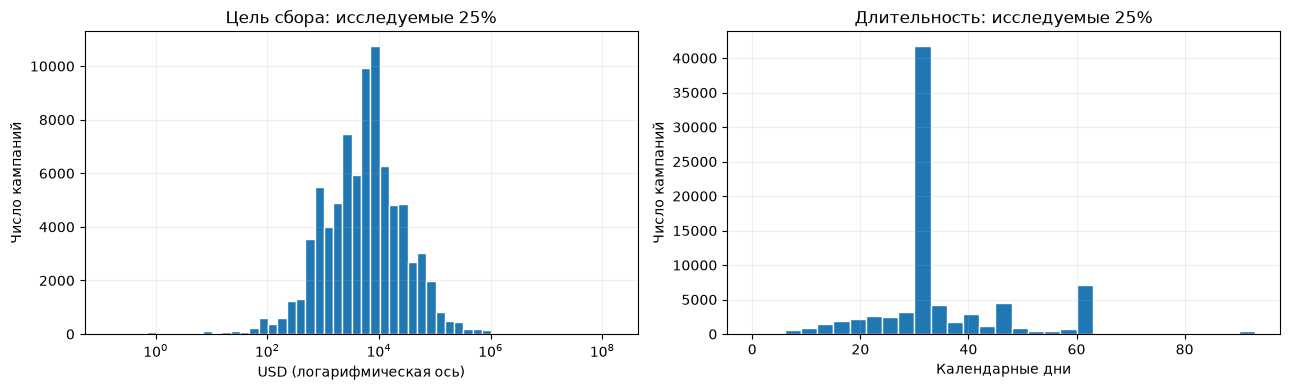

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
goals = eda.usd_goal_real
axes[0].hist(goals, bins=np.geomspace(goals.min(), goals.max(), 55), edgecolor='white')
axes[0].set_xscale('log')
axes[0].set(title='Цель сбора: исследуемые 25%', xlabel='USD (логарифмическая ось)', ylabel='Число кампаний')
axes[1].hist(eda.duration_days, bins=np.arange(0, eda.duration_days.max()+3, 3), edgecolor='white')
axes[1].set(title='Длительность: исследуемые 25%', xlabel='Календарные дни', ylabel='Число кампаний')
plt.tight_layout()
plt.show()

In [18]:
display(Markdown(f'Цель: среднее **{goals.mean():,.2f} USD**, медиана **{goals.median():,.2f} USD**. '
    f'Длинный правый хвост увеличивает среднее. Длительность: среднее **{eda.duration_days.mean():.2f} дня**, '
    f'медиана **{eda.duration_days.median():.0f} дней**.'))

Цель: среднее **43,511.20 USD**, медиана **5,000.00 USD**. Длинный правый хвост увеличивает среднее. Длительность: среднее **33.92 дня**, медиана **30 дней**.

## 5 Связь признаков с успехом
Сравним доли успешных проектов по цели, длительности и категории. Пока используем только первые 25%.

In [19]:
# Дополнительные графики связей с успехом — только на исследуемых 25%.
goal_threshold = float(eda.usd_goal_real.median())
duration_threshold = int(eda.duration_days.mode().iloc[0])
category_stats = eda.groupby('main_category').target.agg(['mean', 'count'])
eligible = category_stats[category_stats['count'] >= 500].sort_values('mean')
assert len(eligible) >= 2
low_category, high_category = eligible.index[0], eligible.index[-1]

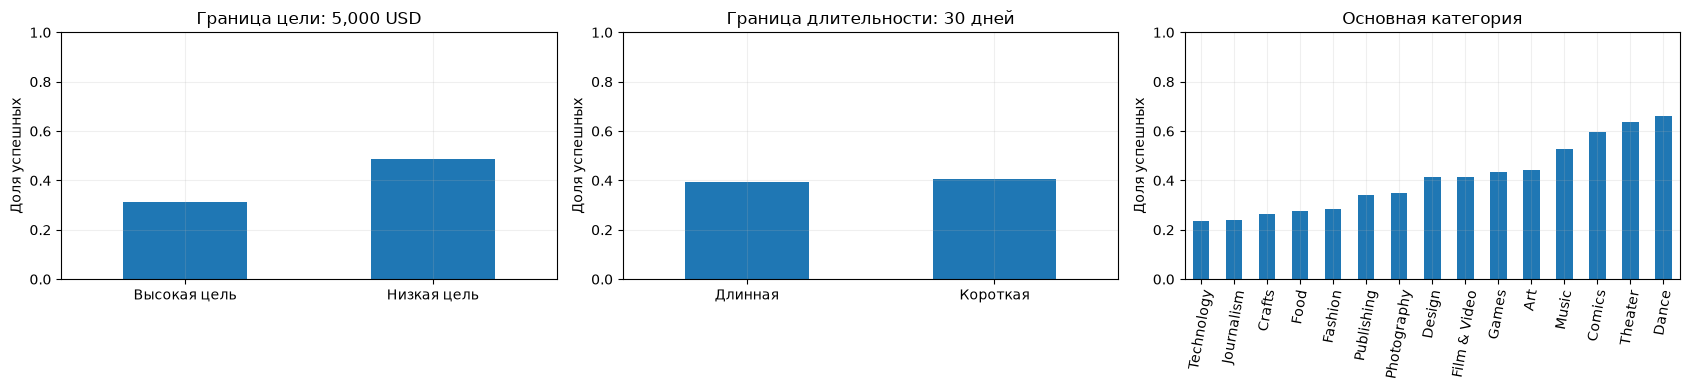

,mean,count
main_category,,
Technology,0.238,6787
Journalism,0.239,1023
Crafts,0.266,1938
Food,0.278,5502
Fashion,0.284,5008
Publishing,0.339,8866
Photography,0.351,2418
Design,0.413,6241
Film & Video,0.415,14164


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
eda.assign(group=np.where(eda.usd_goal_real <= goal_threshold, 'Низкая цель', 'Высокая цель')).groupby('group').target.mean().plot.bar(ax=axes[0], rot=0)
eda.assign(group=np.where(eda.duration_days <= duration_threshold, 'Короткая', 'Длинная')).groupby('group').target.mean().plot.bar(ax=axes[1], rot=0)
category_stats['mean'].sort_values().plot.bar(ax=axes[2], rot=80)
for ax in axes:
    ax.set(ylabel='Доля успешных', ylim=(0, 1), xlabel='')
axes[0].set_title(f'Граница цели: {goal_threshold:,.0f} USD')
axes[1].set_title(f'Граница длительности: {duration_threshold} дней')
axes[2].set_title('Основная категория')
plt.tight_layout()
plt.show()
display(category_stats.sort_values('mean').round(3))

## 6 Гипотезы
**1. Проекты с небольшой целью чаще бывают успешными.** На графике много небольших целей и мало очень больших. Собрать небольшую сумму может быть проще. Поэтому сравним проекты с целью не выше медианы исследуемой части и проекты с целью выше неё. Медиана меньше зависит от выбросов, чем среднее.

**2. Короткие кампании чаще бывают успешными.** На графике длительности заметен наиболее частый срок - мода. Длинные кампании могут быть связаны с более сложными проектами. Проверим, выше ли доля успеха у кампаний со сроком не больше моды, чем у более длинных.

**3. Доля успеха отличается между категориями.** У разных категорий своя аудитория и типичные бюджеты. На первых 25% выбираем категорию с самой высокой и самой низкой долей успеха. Берём только категории, где есть хотя бы 500 проектов, чтобы не выбирать по нескольким случайным примерам. Затем проверяем это различие на остальных 75%.

Категории и пороги после выбора не меняем.

In [21]:
# Все параметры зафиксированы до обращения к confirmation.
hypotheses = [
    ('H1: низкая цель', 'usd_goal_real', goal_threshold),
    ('H2: короткий срок', 'duration_days', duration_threshold),
    ('H3: категория', 'main_category', (high_category, low_category)),
]
print('Зафиксированные гипотезы и пороги:')
for h in hypotheses:
    print(h)

Зафиксированные гипотезы и пороги:
('H1: низкая цель', 'usd_goal_real', 5000.0)
('H2: короткий срок', 'duration_days', 30)
('H3: категория', 'main_category', ('Dance', 'Technology'))


## 7 Проверка гипотез на оставшихся 75%
Для каждой гипотезы сравниваем две доли: `p_A` и `p_B`.
H₀: `p_A <= p_B`, H₁: `p_A > p_B`. Используем односторонний z-тест двух долей. Он подходит при большом числе успехов и неудач; это проверяем в коде.

Уровень значимости - 0,05. Так как проверок три, применяем поправку Холма, чтобы снизить вероятность случайного значимого результата. Если `p_Holm < 0.05`, отклоняем H₀.

Также считаем разницу в процентных пунктах и её 95%-й доверительный интервал. Интервал здесь без поправки на три проверки, поэтому решение принимаем по `p_Holm`.

### 7.1 Функция сравнения долей
Считаем долю успеха в каждой группе, разницу и p-value. Одну функцию используем для всех трёх гипотез.

In [22]:
from scipy.stats import norm

def compare_rates(label, a, b):
    na, nb = len(a), len(b)
    sa, sb = int(a.sum()), int(b.sum())
    assert min(sa, na-sa, sb, nb-sb) >= 10, 'Нормальная аппроксимация ненадёжна'
    pa, pb = sa/na, sb/nb
    pooled = (sa+sb)/(na+nb)
    z = (pa-pb)/np.sqrt(pooled*(1-pooled)*(1/na+1/nb))
    se = np.sqrt(pa*(1-pa)/na + pb*(1-pb)/nb)
    return {'гипотеза': label, 'n_A': na, 'n_B': nb, 'успех_A': pa, 'успех_B': pb,
            'разница_пп': 100*(pa-pb), 'ДИ95_низ_пп': 100*(pa-pb-1.96*se),
            'ДИ95_верх_пп': 100*(pa-pb+1.96*se), 'z': z,
            'p_raw': float(norm.sf(z)), 'log10_p': float(norm.logsf(z)/np.log(10))}

### 7.2 Проверка трёх гипотез
Берём группы из оставшихся 75% и применяем к ним выбранные ранее пороги.

In [23]:
rows = []
for label, col, threshold in hypotheses:
    if col == 'main_category':
        a = confirmation.loc[confirmation[col].eq(threshold[0]), 'target']
        b = confirmation.loc[confirmation[col].eq(threshold[1]), 'target']
    else:
        a = confirmation.loc[confirmation[col] <= threshold, 'target']
        b = confirmation.loc[confirmation[col] > threshold, 'target']
    rows.append(compare_rates(label, a, b))
results = pd.DataFrame(rows)

### 7.3 Поправка на три проверки
Корректируем p-value методом Холма и сравниваем результат с 0,05.

In [24]:
# Холм: сортируем p, умножаем на число оставшихся проверок,
# затем обеспечиваем монотонность скорректированных значений.
p = results.p_raw.to_numpy()
order = np.argsort(p)
adjusted = np.empty(len(p))
adjusted[order] = np.minimum(1, np.maximum.accumulate(p[order]*(len(p)-np.arange(len(p)))))
results['p_Holm'] = adjusted
results['отклоняем_H0'] = results.p_Holm < 0.05
display(results)
print('Если p_raw выведен как 0, это машинное округление; log10_p показывает порядок величины.')

Если p_raw выведен как 0, это машинное округление; log10_p показывает порядок величины.


,гипотеза,n_A,n_B,успех_A,успех_B,разница_пп,ДИ95_низ_пп,ДИ95_верх_пп,z,p_raw,log10_p,p_Holm,отклоняем_H0
0,H1: низкая цель,126031,122717,0.490173,0.316607,17.356655,16.977305,17.736006,88.179825,0.000000e+00,-1690.812316,0.000000e+00,True
1,H2: короткий срок,158587,90161,0.409498,0.395836,1.366129,0.965538,1.766720,6.673397,1.249745e-11,-10.903179,1.249745e-11,True
2,H3: категория,2689,20263,0.651543,0.237971,41.357264,39.463248,43.251279,44.572199,0.000000e+00,-433.450646,0.000000e+00,True


## 8 Выводы
Сравним доли успеха и размер различий. Статистически значимая разница не всегда велика на практике: например, разница по сроку составляет около 1,37 процентного пункта.

In [25]:
for _, r in results.iterrows():
    verdict = 'получила поддержку' if r['отклоняем_H0'] else 'не получила достаточной поддержки'
    display(Markdown(f"**{r['гипотеза']}** {verdict} после поправки Холма. "
        f"Успех: {r['успех_A']:.1%} против {r['успех_B']:.1%}; "
        f"разница **{r['разница_пп']:.2f} п.п.** "
        f"(95% ДИ без поправки: {r['ДИ95_низ_пп']:.2f}…{r['ДИ95_верх_пп']:.2f} п.п.)."))
display(Markdown('Цель сбора имеет выраженную правую асимметрию, поэтому во второй части '
    'сравним обычное масштабирование и логарифмирование. Обнаруженные связи не означают, '
    'что уменьшение цели или срока само по себе вызовет рост успеха: группы отличаются '
    'категориями, годами, странами и другими характеристиками. Данные относятся к 2009–2018 годам; '
    'результаты нельзя автоматически переносить на современные кампании.'))

**H1: низкая цель** получила поддержку после поправки Холма. Успех: 49.0% против 31.7%; разница **17.36 п.п.** (95% ДИ без поправки: 16.98…17.74 п.п.).

**H2: короткий срок** получила поддержку после поправки Холма. Успех: 40.9% против 39.6%; разница **1.37 п.п.** (95% ДИ без поправки: 0.97…1.77 п.п.).

**H3: категория** получила поддержку после поправки Холма. Успех: 65.2% против 23.8%; разница **41.36 п.п.** (95% ДИ без поправки: 39.46…43.25 п.п.).

Цель сбора имеет выраженную правую асимметрию, поэтому во второй части сравним обычное масштабирование и логарифмирование. Обнаруженные связи не означают, что уменьшение цели или срока само по себе вызовет рост успеха: группы отличаются категориями, годами, странами и другими характеристиками. Данные относятся к 2009–2018 годам; результаты нельзя автоматически переносить на современные кампании.